# Experimento CARP para recolección de residuos

Notebook para construir y resolver una instancia pequeña del **Capacitated Arc Routing Problem (CARP)** inspirada en Mourão y Almeida (2000), pero **sin asumir que los arcos incidentes al depósito no tienen demanda**.

### Variables del modelo
* $x_{ij}^r$: Servicio del arco requerido $(i,j)$ en el viaje (*trip*) $r$.
* $y_{ij}^r$: Número de veces que el arco $(i,j)$ se recorre sin servicio en el viaje $r$.
* $F_{in} = X_{in} + Y_{in}$ y $F_{out} = X_{out} + Y_{out}$.

### Componentes modelados
* Continuidad, viajes iniciales/finales/intermedios, conectividad por subconjuntos, capacidad y servicio exacto.

In [1]:
!pip -q install ortools networkx matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.8/29.8 MB 19.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.7/137.7 kB 5.3 MB/s eta 0:00:00


In [2]:
from itertools import chain, combinations
from ortools.sat.python import cp_model
import networkx as nx
import matplotlib.pyplot as plt

## 1. Datos del experimento

In [3]:
B = "B"
D = "D"

urban_nodes = [str(i) for i in range(1, 11)]
V = [B] + urban_nodes + [D]

A = [
    ("B","1"), ("1","B"),
    ("B","6"), ("6","B"),
    ("1","2"), ("2","1"),
    ("1","6"), ("6","1"),
    ("2","3"), ("3","2"),
    ("3","6"),
    ("3","4"), ("4","3"),
    ("6","7"),
    ("7","4"),
    ("4","5"), ("5","4"),
    ("5","7"), ("7","5"),
    ("4","8"),
    ("8","9"), ("9","8"),
    ("8","10"),
    ("10","9"),
    ("5","10"), ("10","5"),
    ("9","D"), ("D","9"),
    ("10","D"), ("D","10")
]
A = list(dict.fromkeys(A))

AR = [
    ("1","2"),
    ("2","1"),
    ("2","3"),
    ("3","2"),
    ("3","6"),
    ("6","7"),
    ("7","4"),
    ("4","5"),
    ("5","7"),
    ("8","10"),
    ("10","D"),
    ("D","9")
]

q = {
    ("1","2"): 5,
    ("2","1"): 3,
    ("2","3"): 4,
    ("3","2"): 2,
    ("3","6"): 4,
    ("6","7"): 3,
    ("7","4"): 5,
    ("4","5"): 4,
    ("5","7"): 2,
    ("8","10"): 4,
    ("10","D"): 3,
    ("D","9"): 3
}

d = {
    ("B","1"):2, ("1","B"):2,
    ("B","6"):2, ("6","B"):2,
    ("1","2"):2, ("2","1"):2,
    ("1","6"):3, ("6","1"):3,
    ("2","3"):2, ("3","2"):2,
    ("3","6"):2,
    ("3","4"):3, ("4","3"):3,
    ("6","7"):2,
    ("7","4"):2,
    ("4","5"):2, ("5","4"):2,
    ("5","7"):2, ("7","5"):2,
    ("4","8"):3,
    ("8","9"):2, ("9","8"):2,
    ("8","10"):2,
    ("10","9"):2,
    ("5","10"):3, ("10","5"):3,
    ("9","D"):4, ("D","9"):4,
    ("10","D"):3, ("D","10"):3
}

c = {
    ("1","2"):3,
    ("2","1"):3,
    ("2","3"):3,
    ("3","2"):3,
    ("3","6"):3,
    ("6","7"):3,
    ("7","4"):3,
    ("4","5"):3,
    ("5","7"):3,
    ("8","10"):3,
    ("10","D"):4,
    ("D","9"):5
}

P = 2
W = 10
L = 6

R = range(1, L + 1)
INITIAL = [1, 2]
FINAL = [3, 4]
INTERMEDIATE = [5, 6]

QT = sum(q[a] for a in AR)

print("Número de nodos:", len(V))
print("Número de arcos:", len(A))
print("Número de arcos requeridos:", len(AR))
print("Demanda total QT =", QT)
print("Capacidad W =", W)
print("Vehículos P =", P)
print("Trips potenciales L =", L)
print("Cota inferior por capacidad =", (QT + W - 1)//W)

Número de nodos: 12
Número de arcos: 30
Número de arcos requeridos: 12
Demanda total QT = 42
Capacidad W = 10
Vehículos P = 2
Trips potenciales L = 6
Cota inferior por capacidad = 5


## 2. Validación de datos

In [4]:
assert set(AR).issubset(set(A))
assert set(q.keys()) == set(AR)
assert set(c.keys()) == set(AR)
assert set(d.keys()) == set(A)

for a in AR:
    assert q[a] > 0
    assert d[a] < c[a], f"No se cumple d < c en {a}"

print("✓ Datos consistentes.")

✓ Datos consistentes.


## 3. Modelo y variables

In [5]:
model = cp_model.CpModel()

x = {
    (r,i,j): model.NewBoolVar(f"x_{r}_{i}_{j}")
    for r in R
    for i,j in AR
}

YMAX = len(A)

y = {
    (r,i,j): model.NewIntVar(0, YMAX, f"y_{r}_{i}_{j}")
    for r in R
    for i,j in A
}

## 4. Funciones auxiliares

In [6]:
def Xin(r, v):
    return sum(x[r,i,j] for i,j in AR if j == v)

def Xout(r, v):
    return sum(x[r,i,j] for i,j in AR if i == v)

def Yin(r, v):
    return sum(y[r,i,j] for i,j in A if j == v)

def Yout(r, v):
    return sum(y[r,i,j] for i,j in A if i == v)

def Fin(r, v):
    return Xin(r, v) + Yin(r, v)

def Fout(r, v):
    return Xout(r, v) + Yout(r, v)

def powerset(iterable):
    items = list(iterable)
    return chain.from_iterable(
        combinations(items, r)
        for r in range(1, len(items) + 1)
    )

def inside(i, j, S):
    return i in S and j in S

def crosses(i, j, S):
    return (i in S) != (j in S)

## 5. Función objetivo

In [7]:
service_cost = sum(
    c[i,j] * x[r,i,j]
    for r in R
    for i,j in AR
)

deadhead_cost = sum(
    d[i,j] * y[r,i,j]
    for r in R
    for i,j in A
)

model.Minimize(service_cost + deadhead_cost)

## 6. Restricción (2): continuidad

In [8]:
for r in R:
    for v in urban_nodes:
        model.Add(Fin(r, v) == Fout(r, v))

## 7. Restricciones de trips

In [9]:
for r in INITIAL:
    model.Add(Fout(r, B) - Fin(r, B) == 1)
    model.Add(Fin(r, D) == 1)
    model.Add(Fout(r, D) == 0)

for r in FINAL:
    model.Add(Fin(r, B) - Fout(r, B) == 1)
    model.Add(Fout(r, D) == 1)
    model.Add(Fin(r, D) == 0)

for r in INTERMEDIATE:
    model.Add(Fout(r, B) - Fin(r, B) == 0)
    model.Add(Fout(r, D) - Fin(r, D) == 0)
    model.Add(Fout(r, D) <= 1)

## 8. Restricción (12): conectividad por subconjuntos

In [10]:
V_without_D = [v for v in V if v != D]
M = len(AR) + len(A) * YMAX

count_connectivity = 0

for r in R:
    for subset in powerset(V_without_D):
        S = set(subset)

        inside_flow = (
            sum(x[r,i,j] for i,j in AR if inside(i,j,S))
            +
            sum(y[r,i,j] for i,j in A if inside(i,j,S))
        )

        crossing_flow = (
            sum(x[r,i,j] for i,j in AR if crosses(i,j,S))
            +
            sum(y[r,i,j] for i,j in A if crosses(i,j,S))
        )

        model.Add(inside_flow <= M * crossing_flow)
        count_connectivity += 1

print("Restricciones de conectividad:", count_connectivity)

Restricciones de conectividad: 12282


## 9. Restricción (13): capacidad

In [11]:
load = {}

for r in R:
    load[r] = model.NewIntVar(0, W, f"load_{r}")

    model.Add(
        load[r] ==
        sum(q[i,j] * x[r,i,j] for i,j in AR)
    )

    model.Add(load[r] <= W)

## 10. Restricción (14): servicio exacto

In [12]:
for i,j in AR:
    model.Add(sum(x[r,i,j] for r in R) == 1)

## 11. Resolver

In [13]:
solver = cp_model.CpSolver()
solver.parameters.max_time_in_seconds = 120
solver.parameters.num_search_workers = 8
solver.parameters.log_search_progress = False

status = solver.Solve(model)

print("=" * 60)
print("Estado:", solver.StatusName(status))

if status in [cp_model.OPTIMAL, cp_model.FEASIBLE]:
    print(f"Costo total = {solver.ObjectiveValue():.0f}")

    sc = sum(
        c[i,j] * solver.Value(x[r,i,j])
        for r in R
        for i,j in AR
    )

    dc = sum(
        d[i,j] * solver.Value(y[r,i,j])
        for r in R
        for i,j in A
    )

    print("Costo servicio    =", sc)
    print("Costo deadheading =", dc)

Estado: OPTIMAL
Costo total = 89
Costo servicio    = 39
Costo deadheading = 50


## 12. Revisar trips y capacidad

In [14]:
if status in [cp_model.OPTIMAL, cp_model.FEASIBLE]:

    for r in R:
        tipo = "INICIAL" if r in INITIAL else ("FINAL" if r in FINAL else "INTERMEDIO")

        print("\n" + "="*70)
        print(f"TRIP {r} | {tipo}")
        print("="*70)

        serviced = [(i,j) for i,j in AR if solver.Value(x[r,i,j]) == 1]
        deadheaded = [(i,j,solver.Value(y[r,i,j])) for i,j in A if solver.Value(y[r,i,j]) > 0]

        print("\nArcos SERVIDOS:")
        if serviced:
            for i,j in serviced:
                print(f"  {i:>2} -> {j:<2} | q={q[i,j]} | c={c[i,j]}")
        else:
            print("  Ninguno")

        print("\nArcos DEADHEADING:")
        if deadheaded:
            for i,j,k in deadheaded:
                print(f"  {i:>2} -> {j:<2} | veces={k} | d={d[i,j]}")
        else:
            print("  Ninguno")

        carga = solver.Value(load[r])
        carga_recalculada = sum(q[i,j] * solver.Value(x[r,i,j]) for i,j in AR)

        print("\nCapacidad:")
        print(f"  load del modelo   = {carga}/{W}")
        print(f"  carga recalculada = {carga_recalculada}/{W}")

        assert carga == carga_recalculada
        assert carga <= W
        assert carga_recalculada <= W

    print("\n✓ Todas las restricciones de capacidad verificadas.")


TRIP 1 | INICIAL

Arcos SERVIDOS:
   1 -> 2  | q=5 | c=3
   8 -> 10 | q=4 | c=3

Arcos DEADHEADING:
   B -> 1  | veces=1 | d=2
   2 -> 3  | veces=1 | d=2
   3 -> 4  | veces=1 | d=3
   4 -> 8  | veces=1 | d=3
  10 -> D  | veces=1 | d=3

Capacidad:
  load del modelo   = 9/10
  carga recalculada = 9/10

TRIP 2 | INICIAL

Arcos SERVIDOS:
   6 -> 7  | q=3 | c=3
   4 -> 5  | q=4 | c=3
  10 -> D  | q=3 | c=4

Arcos DEADHEADING:
   B -> 6  | veces=1 | d=2
   7 -> 4  | veces=1 | d=2
   5 -> 10 | veces=1 | d=3

Capacidad:
  load del modelo   = 10/10
  carga recalculada = 10/10

TRIP 3 | FINAL

Arcos SERVIDOS:
   2 -> 1  | q=3 | c=3
   7 -> 4  | q=5 | c=3
   5 -> 7  | q=2 | c=3

Arcos DEADHEADING:
   1 -> B  | veces=1 | d=2
   3 -> 2  | veces=1 | d=2
   4 -> 3  | veces=1 | d=3
  10 -> 5  | veces=1 | d=3
   D -> 10 | veces=1 | d=3

Capacidad:
  load del modelo   = 10/10
  carga recalculada = 10/10

TRIP 4 | FINAL

Arcos SERVIDOS:
   2 -> 3  | q=4 | c=3
   3 -> 2  | q=2 | c=3
   3 -> 6  | q=4 | c=

## 13. Verificar arcos requeridos

In [15]:
if status in [cp_model.OPTIMAL, cp_model.FEASIBLE]:

    total_served = 0

    for i,j in AR:
        trips = [r for r in R if solver.Value(x[r,i,j]) == 1]
        print(f"{i:>2} -> {j:<2} | q={q[i,j]} | trip={trips}")
        assert len(trips) == 1
        total_served += q[i,j]

    print("\nDemanda total atendida:", total_served, "/", QT)
    assert total_served == QT

 1 -> 2  | q=5 | trip=[1]
 2 -> 1  | q=3 | trip=[3]
 2 -> 3  | q=4 | trip=[4]
 3 -> 2  | q=2 | trip=[4]
 3 -> 6  | q=4 | trip=[4]
 6 -> 7  | q=3 | trip=[2]
 7 -> 4  | q=5 | trip=[3]
 4 -> 5  | q=4 | trip=[2]
 5 -> 7  | q=2 | trip=[3]
 8 -> 10 | q=4 | trip=[1]
10 -> D  | q=3 | trip=[2]
 D -> 9  | q=3 | trip=[6]

Demanda total atendida: 42 / 42


## 14. Dibujar la instancia

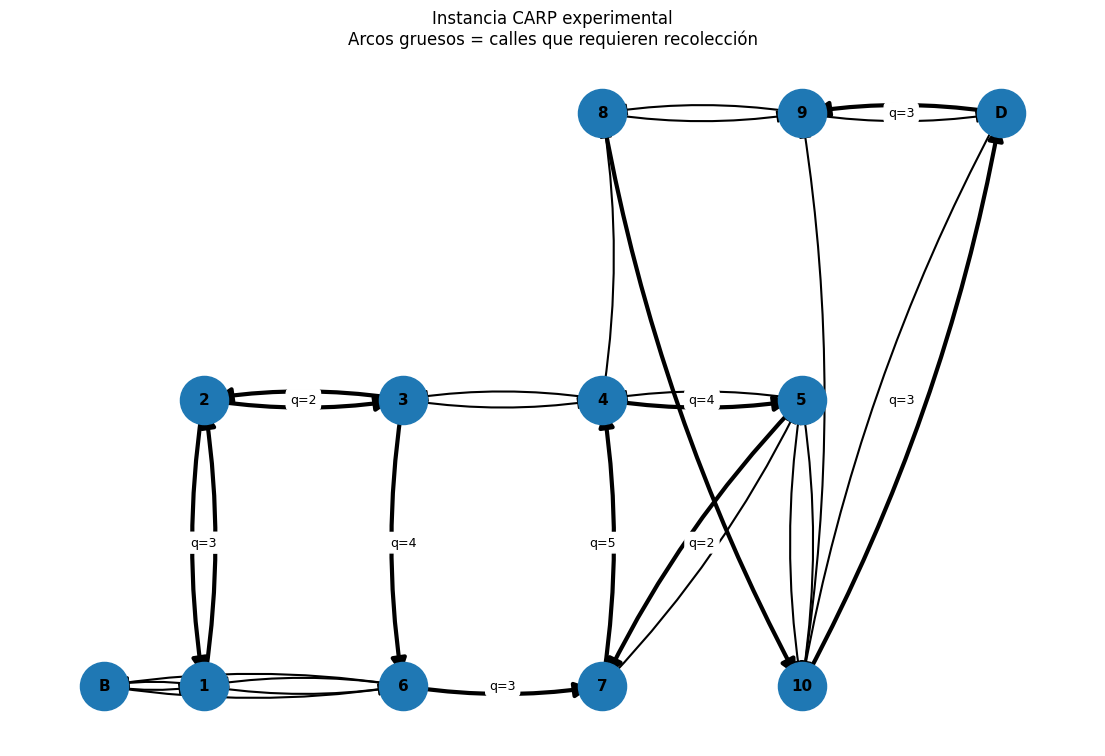

In [16]:
G = nx.DiGraph()
G.add_nodes_from(V)
G.add_edges_from(A)

pos = {
    "B":  (-1, 0),
    "1":  (0, 0),
    "2":  (0, 2),
    "3":  (2, 2),
    "4":  (4, 2),
    "5":  (6, 2),
    "6":  (2, 0),
    "7":  (4, 0),
    "8":  (4, 4),
    "9":  (6, 4),
    "10": (6, 0),
    "D":  (8, 4)
}

plt.figure(figsize=(14, 9))

nx.draw_networkx_nodes(G, pos, node_size=1200)
nx.draw_networkx_labels(G, pos, font_size=11, font_weight="bold")

non_required = [a for a in A if a not in AR]

nx.draw_networkx_edges(
    G, pos,
    edgelist=non_required,
    arrows=True,
    arrowsize=18,
    width=1.5,
    connectionstyle="arc3,rad=0.08"
)

nx.draw_networkx_edges(
    G, pos,
    edgelist=AR,
    arrows=True,
    arrowsize=22,
    width=3,
    connectionstyle="arc3,rad=0.08"
)

edge_labels = {(i,j): f"q={q[i,j]}" for i,j in AR}

nx.draw_networkx_edge_labels(
    G, pos,
    edge_labels=edge_labels,
    font_size=9,
    rotate=False
)

plt.title("Instancia CARP experimental\nArcos gruesos = calles que requieren recolección")
plt.axis("off")
plt.show()

## Observaciones

- No se asume que los arcos incidentes al depósito carecen de demanda.
- Las restricciones especiales de base y depósito usan \(F=X+Y\).
- La restricción (12) se genera con `powerset`.
- La capacidad se modela con `load[r]` y se verifica de nuevo al final.
- Si aparece una carga mayor que \(W\), las aserciones detienen la ejecución.